<a href="https://colab.research.google.com/github/IsaacFayle-Waters/Multihead-Context_Aware-RoBERTa-for-Dialogue-Act-Classification/blob/main/multihead_context_aware_dialogue_act_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multihead context-aware RoBERTa for Dialogue Act Classification

### Environment
To re-run this notebook, you will need to obtain the DailyDialog dataset associated with (Li, et al, 2017) Dailydialog: a Manually Labelled multi-turn Dialogue dataset.

### Comet Set-up

In [ ]:
api_key = userdata.get('COMET_ML_KEY')
#Comet ML
import comet_ml
from comet_ml import Optimizer
comet_ml.login(api_key=api_key)

experiment = comet_ml.start(
    project_name="dailydialogue-mllv_full",
    workspace="isaac-fayle-waters"

)

COMET INFO: Valid Comet API Key saved in /home/jovyan/.comet.config (set COMET_CONFIG to change where it is saved).
COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/isaac-fayle-waters/dailydialogue-mllv-full/7e54f22938e7435f97b5bea2b8c8e86e



In [ ]:
import pandas as pd
import numpy as np
import math
import unidecode
import unicodedata
import string
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import re
from collections import defaultdict
from datasets import Dataset

#Model
import torch
import torch.nn as nn
from transformers import pipeline, TrainingArguments,Trainer
from transformers import RobertaTokenizerFast, RobertaForSequenceClassification, RobertaModel
from transformers import DataCollatorWithPadding,EarlyStoppingCallback

#Metrics
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

#Saving models

from huggingface_hub import login
from huggingface_hub import HfApi
from google.colab import userdata
HUG_FACE_KEY = userdata.get('HF_TOKEN')
login(token=HUG_FACE_KEY)### Imports


COMET INFO: Couldn't find a Git repository in '/home/jovyan/ML-LV/Week6' nor in any parent directory. Set `COMET_GIT_DIRECTORY` if your Git Repository is elsewhere.


### Data Unification

In [ ]:
#Unify dialogue data and convert to dataframe
data = {
    'Dialogue': dialogues,
    'Emotion': emotions,
    'Dialogue_Act': dialogue_acts,
    'Topic': topics
       }

df = pd.DataFrame(data=data)
df_raw = df.copy()

topic_mapping = {
    1: 'Ordinary Life',
    2: 'School Life',
    3: 'Culture & Education',
    4: 'Attitude & Emotion',
    5: 'Relationship',
    6: 'Tourism' ,
    7: 'Health',
    8: 'Work',
    9: 'Politics',
    10: 'Finance'
}

act_mapping = {
    1: 'inform',
    2: 'question',
    3: 'directive',
    4: 'commissive'
}

emotion_mapping = {
    0: 'no emotion',
    1: 'anger',
    2: 'disgust',
    3: 'fear',
    4: 'happiness',
    5: 'sadness',
    6: 'surprise'
}

### Configuration

In [ ]:
#Configuration (initial parameters)
MODIFIYER_TEST = 1 #Test conditions to limit data being used. 4 = 1/4, 1 = 1/1
CONTEXT = True #Whether to use context or not
MODEL_NAME = 'roberta-base'
PROJECT_NAME = 'dailydialogue-mllv-full'
MAX_LENGTH = 128 #Tokens
MAX_CHAR_LENGTH = 500 #Characters
BATCH_SIZE = 16
NUM_EPOCHS = 8
NUM_DA_LABELS = list(act_mapping.keys())[-1]
NUM_TOPIC_LABELS = list(topic_mapping.keys())[-1]
LEARNING_RATE = 2e-5 #for construction, will tune params with comet

experiment.log_parameters({
    "model": MODEL_NAME,
    "experiment_name": PROJECT_NAME,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "num_epochs": NUM_EPOCHS,
})

### Function Definitions: Analysis

In [ ]:
'''LLM USAGE: THIS FUNCTION WAS FINALISED BY A COLAB GEMINI INSTANCE BASED ON MY ORIGNAL CODE  '''
def collect_counts(df_input, emo=True): # FINALISED BY COLAB GEMINI INSTANCE
    # 1. Initialize empty lists
    emo_counts = []
    dia_act_counts = []
    topic_counts = []
    dialogue_utt_count = []

    # 2. Extract counts for emotions and dialogue acts (utterance level)
    if emo:
      for emo_list in df_input['Emotion']:
          for emo in emo_list:
              emo_counts.append(int(emo))

    for act_list in df_input['Dialogue_Act']:
        for act in act_list:
            dia_act_counts.append(int(act))

    # 3. Extract topic counts (dialogue level)
    for topic in df_input['Topic']:
        topic_counts.append(int(topic))

    # 4. Process utterances per dialogue
    for dialogue_str in df_input['Dialogue']:
        # Split by __eou__ and filter out empty strings to get true utterance count
        utt_list = [u for u in dialogue_str.split('__eou__') if u.strip()]
        dialogue_utt_count.append(len(utt_list))

    # 5. Construct return dictionaries
    count_data = {
        'emotion_count': emo_counts,
        'dia_act_count': dia_act_counts
    }
    utt_topic_data = {
        'utt_counts': dialogue_utt_count,
        'topic_counts': topic_counts
    }

    return count_data, utt_topic_data

def create_mapped_df(data, mappings):#From CHATGPT
    """
    Create a DataFrame and apply multiple mappings from unified data .

    Parameters:
        data (list/dict): Input data for DataFrame
        mappings (dict): {
            'original_col': ('new_col_name', mapping_dict)
        }

    Returns:
        pd.DataFrame
    """
    df = pd.DataFrame(data=data)#Create DF from input
    #Map df to mapping strings
    for col, (new_col, mapping_dict) in mappings.items():
        df[new_col] = df[col].map(mapping_dict)

    return df

def plot_dialogue_distributions(
    df_to_plot,
    counts_df=None,
    emo=True,
    dia=True,
    topic=True,
    length=True,
    ):
    """LLM USAGE: WRITTEN BY GEMINI. TIDIED BY CLAUDE.
    Plots distributions for Emotions, Dialogue Acts, Topics, and Dialogue Lengths.

    Args:
        df_to_plot (pd.DataFrame): The main dialogue dataframe (containing Topic and num_utterance).
        counts_df (pd.DataFrame): The utterance-level dataframe (containing emo_mapping and dia_act_mapping).
                                  If None, it assumes the metrics are columns in df_to_plot.
        emo (bool): Whether to plot the emotion distribution. Defaults to True.
        dia (bool): Whether to plot the dialogue act distribution. Defaults to True.
        topic (bool): Whether to plot the topic distribution. Defaults to True.
        length (bool): Whether to plot the dialogue length distribution. Defaults to True.
    """
    sns.set_theme(style="whitegrid")

    plots_to_generate = []
    if emo: plots_to_generate.append('emotion')
    if dia: plots_to_generate.append('dialogue_act')
    if topic: plots_to_generate.append('topic')
    if length: plots_to_generate.append('length')

    num_plots_to_show = len(plots_to_generate)

    if num_plots_to_show == 0:
        print("No plots requested.")
        return

    # Determine grid size based on the number of plots to generate
    # Max 2 columns for better readability/layout, dynamically calculate rows
    num_cols_in_grid = min(num_plots_to_show, 2)
    num_rows_in_grid = math.ceil(num_plots_to_show / num_cols_in_grid) if num_cols_in_grid > 0 else 0

    if num_rows_in_grid == 0:
        print("No plots requested for grid.")
        return

    # Create the figure and subplots
    fig, axes = plt.subplots(num_rows_in_grid, num_cols_in_grid, figsize=(18, 6 * num_rows_in_grid))

    # Ensure axes is always a 1D array of axes objects for easy iteration
    if num_plots_to_show == 1:
        axes = [axes] # If only one plot, plt.subplots returns a single axis object, not an array
    else:
        axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

    target_df_emo = counts_df if counts_df is not None else df_to_plot
    plot_idx = 0

    if 'emotion' in plots_to_generate:
        # 1. Distribution of Emotions
        ax = axes[plot_idx]
        sns.countplot(data=target_df_emo, x='emo_mapping', hue='emo_mapping', ax=ax, palette='viridis',
                      order=target_df_emo['emo_mapping'].value_counts().index, legend=False)
        ax.set_title('Distribution of Emotions', fontsize=15)
        ax.tick_params(axis='x', rotation=45)
        plot_idx += 1

    if 'dialogue_act' in plots_to_generate:
        # 2. Distribution of Dialogue Acts
        ax = axes[plot_idx]
        sns.countplot(data=target_df_emo, x='dia_act_mapping', hue='dia_act_mapping', ax=ax, palette='magma',
                      order=target_df_emo['dia_act_mapping'].value_counts().index, legend=False)
        ax.set_title('Distribution of Dialogue Acts', fontsize=15)
        ax.tick_params(axis='x', rotation=45)
        plot_idx += 1

    if 'topic' in plots_to_generate:
        # 3. Distribution of Conversation Topics
        ax = axes[plot_idx]
        sns.countplot(data=df_to_plot, x='topic_mapping', hue='topic_mapping', ax=ax, palette='rocket',
                      order=df_to_plot['topic_mapping'].value_counts().index, legend=False)
        ax.set_title('Distribution of Conversation Topics', fontsize=15)
        ax.tick_params(axis='x', rotation=45)
        plot_idx += 1

    if 'length' in plots_to_generate:
        # 4. Distribution of Dialogue Lengths
        ax = axes[plot_idx]
        sns.histplot(df_to_plot['num_utterance'], bins=30, ax=ax, color='teal', kde=True)
        ax.set_title('Distribution of Dialogue Lengths', fontsize=15)
        ax.set_xlabel('Number of Utterances per Dialogue')
        plot_idx += 1

    # Remove any unused subplots (relevant if num_plots_to_show is odd and num_cols_in_grid is 2)
    total_axes_created = num_rows_in_grid * num_cols_in_grid
    for j in range(plot_idx, total_axes_created):
        # Ensure the index is within the bounds of the actual axes array
        if j < len(axes): # This check is redundant with the previous logic now but harmless
            fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

## Preprocessing and Analysis
#### Initial Inspection

Initial checks reveal no null values. Unique labels for `Emotion` and `Dialogue_Act` classes were in the thousands, while further inspection revealed `list` representations that had been cast to `str` form, with irregular white spacing. The mapping dictionaries included 21 class labels. This task has been interpreted as a multiclass dialogue act classification problem.

The length of the label `lists` correspond with the frequency of `__eou__` tags found within the `dialogue` texts. These mark ‘utterances’ to be classified.   

### Pre-processing

The choice of model and problem governs the pre-processing steps necessary. For this project RoBERTa has been chosen as the base model, which during tokenization uses Byte Pair Encoding (BPE) (Liu et al., 2019\) at byte-level, as previously used for training GPT-2 (Radford et al., 2019). This method was developed with generalisation in mind, the upshot of which is that minimal pre-processing is necessary (Radford et al., 2019). More traditional methods of pre-processing are therefore inappropriate, i.e. removing URLs, lowering cases, etc.

#### Whitespace

`regex` methods were used to remove ‘unrealistic’ whitespace elements from both the `Dialogue` text, and the class labels \- `Emotion` and `Dialogue_Act`. In particular, efforts were made to ensure white spacing around punctuation reflected usual grammatical form.

#### Duplicates

742 duplicate `Dialogue` texts were discovered and dropped.

#### Limiting Excessive `Dialogue`

There are limiting factors affecting the amount of data considered. Firstly, the Jupyter environment only supports Python at CPU level. Secondly, there are economic, computational, and environmental costs involved in training which make setting a limit desirable: this task is essentially a demonstration of ability rather than for a specified need. Thirdly, tokens in RoBERTa are truncated to 512 (FacebookAI, 2024), while the longest character length of a `dialogue` is 4221, or \~3165 tokens (OpenAI, n.d.).

Character `MAX_CHAR_LENGTH` is set to 500: dialogues over this are rejected. `MAX_LENGTH` limits tokens accepted at 128 per sequence. 5.6% of utterances are above this. This is acceptable as some truncation is likely to occur naturally.

### Basic Checks

In [ ]:
#Basic investigation of the unified data
print(df.info())
print('_'*75)

print('Number of unique labels per class:')
non_txt = ['Emotion','Dialogue_Act' ,'Topic']
print(df[non_txt].nunique())
print('_'*75)

#Val counts and oveview of label problems, i.e. whitespace
print('Value counts and overview of label problems:')
for col in non_txt:
    print(df[col].value_counts())
    print('_'*75)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13118 entries, 0 to 13117
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Dialogue      13118 non-null  object
 1   Emotion       13118 non-null  object
 2   Dialogue_Act  13118 non-null  object
 3   Topic         13118 non-null  object
dtypes: object(4)
memory usage: 410.1+ KB
None
___________________________________________________________________________
Number of unique labels per class:
Emotion         2757
Dialogue_Act    5752
Topic             10
dtype: int64
___________________________________________________________________________
Value counts and overview of label problems:
Emotion
0 0 0 0 \n                        1484
0 0 0 0 0 0 \n                     722
0 0 0 0 0 \n                       604
0 0 0 0 0 0 0 0 \n                 540
0 0 0 0 0 0 0 0 0 0 \n             531
                                  ... 
0 0 4 0 4 0 0 4 0 0 0 0 4 0 \n       1
0 0 

### Initial Pre-Processing

#### Whitespace Removal

In [ ]:
'''LLM USAGE: GPT assistance with modifying stackoverflow code, and capturing odd punctuation'''
#https://stackoverflow.com/a/18878970
#https://chatgpt.com/share/69d8dc80-54f4-8332-be7f-1ee05460f32c
#Remove unnecesary whitespace characters from all columns
punct = re.escape(string.punctuation)
for col in df.columns:
    df[col] = df[col].str.replace(r'[^\S ]+', '', regex=True)
    df[col] = df[col].str.replace(r"\s*’\s*", "’", regex=True)
    df[col] = df[col].str.replace(rf'\s([{punct}](?:\s|$))', r'\1', regex=True)

df.Dialogue.iloc[2]

'Are things still going badly with your houseguest? __eou__ Getting worse. Now he’s eating me out of house and home. I’Ve tried talking to him but it all goes in one ear and out the other. He makes himself at home, which is fine. But what really gets me is that yesterday he walked into the living room in the raw and I had company over! That was the last straw. __eou__ Leo, I really think you’re beating around the bush with this guy. I know he used to be your best friend in college, but I really think it’s time to lay down the law. __eou__ You’re right. Everything is probably going to come to a head tonight. I’ll keep you informed. __eou__'

In [ ]:
#SEARCH CONDTIONS CREATED BY GEMINI

#Regex pattern for simple URL matching (and for oddly formatted i.e. 'www .pies.com')
url_pattern = r'https?:\/\/\s*\S+|www\.\s*\S+'

# Find dialogues containing URLs
dialogues_with_urls = df[df['Dialogue'].str.contains(url_pattern, case=False, na=False, regex=True)]

print(f'Number of dialogues containing URLs: {len(dialogues_with_urls)}')

if len(dialogues_with_urls) > 0:
    # Set pandas options to show full column width and all rows
    with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
        display(dialogues_with_urls[['Dialogue']])

Number of dialogues containing URLs: 9


,Dialogue
224,I am keen on a coat on www.dingding.com. But it requires having an online banking account. Is it necessary? __eou__ Indeed. Online banking enables you to make on-line shopping. __eou__ Do you know how to get the bank account? __eou__ Bring your ID card and fill out a form. That will be fine. __eou__ So easy. __eou__ I think online banking can change your money habits and it is quicker than ATM processing speed. __eou__ My shopping life will be more convenient. __eou__
2873,"I really want to go to China for vacation, but I can't find a cheap plane ticket. __eou__ Have you tried the Internet? __eou__ No, not yet. Can you find a good price there? __eou__ Wow, you really live in the Stone Age, Mom. __eou__ Well, you don't have to be mean. How do I do it? __eou__ Go to www.yahoo.com and click on Travel and tickets. There are about a billion sites to look at. __eou__ Ok, thanks. I'll let you know what I find. __eou__ All right. __eou__ I’ll look for a ticket for you, too. Thanks! __eou__"
2993,"How do I set up an E-mail account? __eou__ Oh, that's easy. Go to www.onxiu.cn. Now, click on the link with the picture of an envelope. __eou__ Which link? __eou__ That one, the one that says Mail. __eou__ Oh, no. What did I do? It's asking me for a password. __eou__ Don't worry. See where it says, New User? __eou__ Yes. __eou__ Click on that. __eou__ Oh, I see. __eou__ Yeah, just fill out this form and choose a password. The computer will do the rest. __eou__"
3878,"Can you help me do an internet search? __eou__ Sure. What do you want to find? __eou__ I want to find information on World War Two. __eou__ Well, can you be more specific? There are a lot of websites about that. __eou__ Yes, I want to know about the Normandy Landing. __eou__ Ok. Well, go to www.google.com, and type in Normandy Landing. __eou__ Oh, wow! There are lot of sites. __eou__ Here, try this one. It's a good site about Normandy Landing. __eou__ Thanks. __eou__ For detailed information, however, you should read a history book. __eou__ Thanks. If I am interested, I'll go to the library. __eou__"
5828,"Do you know who Ammo Hung is? __eou__ Of course. He is now 50 years old. And he started out studying alembics, singing, dancing and martial arts at the age of nine, and has tarred in 140 kung fu films. He has also become an independent producer and director. __eou__ You know only one aspect of him. Do you know what he would do in the kitchen? __eou__ I have no idea. Tell me. __eou__ In the kitchen, with his wife by his side he still puts on quite a dinner time show. __eou__ What does he do there? __eou__ Imagine a chef chopping vegetables on fast forward. Picture a man making a stir-fry, tossing the mixture up in the air, and then catching it, every last bit, in his work. And his culinary motto is' Enjoy the moment. ' If you want to know hey theycook, visit www.StudioClassroom.com.tw for the recipe. __eou__"
5897,"Hi. Have you got a personal computer? __eou__ Certainly. What's the matter? __eou__ I wonder if you often trade with others on the internet. __eou__ Sure. I often buy things or do business through it without going out to the physical stores. __eou__ Great! It's just like viewless stores. But how can you shop or order on line or trade on line? __eou__ That's simple. Just click the hyperlink, www.taobao.com or www. ebay.com, and you can see the specimen of the goods shown on the screen, and then you can place an order online with the sales company. And the goods will be delivered to your place. __eou__ Is the service charged? __eou__ No. it's free. __eou__ Really. I'll get a computer at once. __eou__"
10748,"OK! Let's get down to business now. __eou__ Say it. __eou__ As you know, we should work out cautious and detailed plan for our promotion, so as to guide our company to be successful in the new product, L-series. __eou__ That's right. And in my opinion, to push the sale of the new products is not an easy task. __eou__ I know that. I need to discuss this

In [ ]:
#Strip newline character from topic and set dtype to numeric
df['Topic'] = pd.to_numeric(df.Topic)
display(df.Topic.value_counts())

Topic
5     4391
1     3646
8     1924
6     1065
4      667
2      487
10     485
7      267
9      131
3       55
Name: count, dtype: int64

In [ ]:
#Set Emotion and Dialogue_Act to lists of integers
for col in ['Emotion','Dialogue_Act']:
    #df[col] = df[col].str.strip()
    df[col] = df[col].str.split().apply(lambda x: [int(i) for i in x])

print('Value counts post-cleaning')
for col in non_txt:
    print(df[col].value_counts())
    print('_'*75)

display(df.head())### Basic Checks

Value counts post-cleaning
Emotion
[0, 0, 0, 0]                                  1484
[0, 0, 0, 0, 0, 0]                             722
[0, 0, 0, 0, 0]                                604
[0, 0, 0, 0, 0, 0, 0, 0]                       540
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]                 531
                                              ... 
[0, 0, 4, 0, 4, 0, 0, 4, 0, 0, 0, 0, 4, 0]       1
[0, 0, 0, 0, 0, 0, 4, 4, 0, 5, 0, 0]             1
[0, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 4]             1
[0, 0, 4, 4, 4, 0, 4, 4, 0, 0, 0, 4]             1
[0, 0, 0, 0, 0, 0, 0, 2]                         1
Name: count, Length: 2757, dtype: int64
___________________________________________________________________________
Dialogue_Act
[2, 1, 2, 1]                                     400
[1, 1, 1, 1]                                     250
[2, 1, 1, 1]                                     223
[1, 1]                                           201
[2, 1]                                           183
          

,Dialogue,Emotion,Dialogue_Act,Topic
0,The kitchen stinks. __eou__ I'll throw out the...,"[2, 0]","[3, 4]",1
1,"So Dick, how about getting some coffee for ton...","[4, 2, 0, 1, 0]","[3, 4, 3, 1, 1]",1
2,Are things still going badly with your housegu...,"[0, 1, 0, 0]","[2, 1, 3, 4]",1
3,"Would you mind waiting a while? __eou__ Well, ...","[0, 0, 0, 4]","[3, 2, 1, 1]",1
4,Are you going to the annual party? I can give ...,"[0, 4, 4]","[3, 4, 1]",1


#### Remove Duplicates

In [ ]:
df.shape

(13118, 4)

In [ ]:
dupes = df[df.duplicated(subset=["Dialogue"])]
print(f"Number of duplicated dialogues = {len(dupes)}")


df = df.drop_duplicates(subset=['Dialogue'])

display(df.shape)

Number of duplicated dialogues = 742


(12376, 4)

#### Limit Excessive Dialogues
No very short dialogues have been found, though there are excessivly long ones.

In [ ]:
df['Dialogue_length'] = df.Dialogue.str.len()
display('Minimum Dialogue Length:',df['Dialogue_length'].min())
display('Maximum Dialogue Length:',df['Dialogue_length'].max())
longest = df[df.Dialogue_length == 4221]
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
  display(longest.Dialogue)

'Minimum Dialogue Length:'

33

'Maximum Dialogue Length:'

4221

12073    Let's begin by having you tell me about yourself and your background. __eou__ I have been working as a paralegal for the last 10 months through an agency that specializes in the legal field. My experience has been supporting attorneys in the field of labor law, where I have been able to apply my paralegal education. I was commended on my ability to take information and break it down into usable facts. I really love research and analyzing facts. My major in college was English, and as a result, my writing skills are my major strength. I am looking for a position where my research and writing skills can be used. __eou__ What do you think are the key qualities needed to succeed in the paralegal profession? __eou__ Flexibility would certainly rank high in this type of job. In my last position, I supported four lawyers, and it was not unusual for them all to give me high-priority items to do in the same day or week. There were days when I had to stop and prioritize my work just to 

In [ ]:
count_data, utt_topic_data = collect_counts(df)

print(f"Total utterances found : {len(count_data['emotion_count'])}")
print(f"Total dialogues processed: {len(utt_topic_data['utt_counts'])}")

Total utterances found : 97651
Total dialogues processed: 12376


In [ ]:
df_counts = create_mapped_df(count_data, {'emotion_count': ('emo_mapping', emotion_mapping),
                                          'dia_act_count': ('dia_act_mapping', act_mapping)})

df_utt_top_counts = create_mapped_df(utt_topic_data, {'utt_counts': ('topic_mapping', topic_mapping)})

df = df.reset_index(drop=True)
df['topic_mapping'] = df_utt_top_counts['topic_mapping']
df['num_utterance'] = df_utt_top_counts['utt_counts']

df[['num_utterance','Dialogue_length']].describe()

df[['num_utterance','Dialogue_length']].quantile(q=np.arange(0,1.01,0.25))

np.sum(df.Dialogue_length < 700)

df_shorter_length = df[df.Dialogue_length < 701]

df_shorter_length[['num_utterance','Dialogue_length']].describe()

,num_utterance,Dialogue_length
count,9354.000000,9354.000000
mean,6.595040,359.622087
std,3.026241,167.985842
min,2.000000,33.000000
25%,4.000000,220.000000
50%,6.000000,350.000000
75%,9.000000,491.000000
max,20.000000,700.000000


## Graphic Analysis

Immediately noticeable in the plotting is that `no_emotion` outweighs all other `Emotion` labels. As such, `Emotion` classification is not considered. There are also less prominent imbalances within `Topic` and `Dialogue_Act`. Similar patterns continue after truncation.

There was initial interest in focusing solely on bi-turn dialogues, however this would have induced further imbalance. Non-standard dialogue pairs, (Question-Commission) were investigated, but none found (Li et al., 2017). Because the data has been truncated, more bi-turn flows are expected to have been included, but longer patterns persist.



### Collect Counts for Analysis

In [ ]:
count_data, utt_topic_data = collect_counts(df)

print(f"Total utterances found : {len(count_data['emotion_count'])}")
print(f"Total dialogues processed: {len(utt_topic_data['utt_counts'])}")

Total utterances found : 97651
Total dialogues processed: 12376


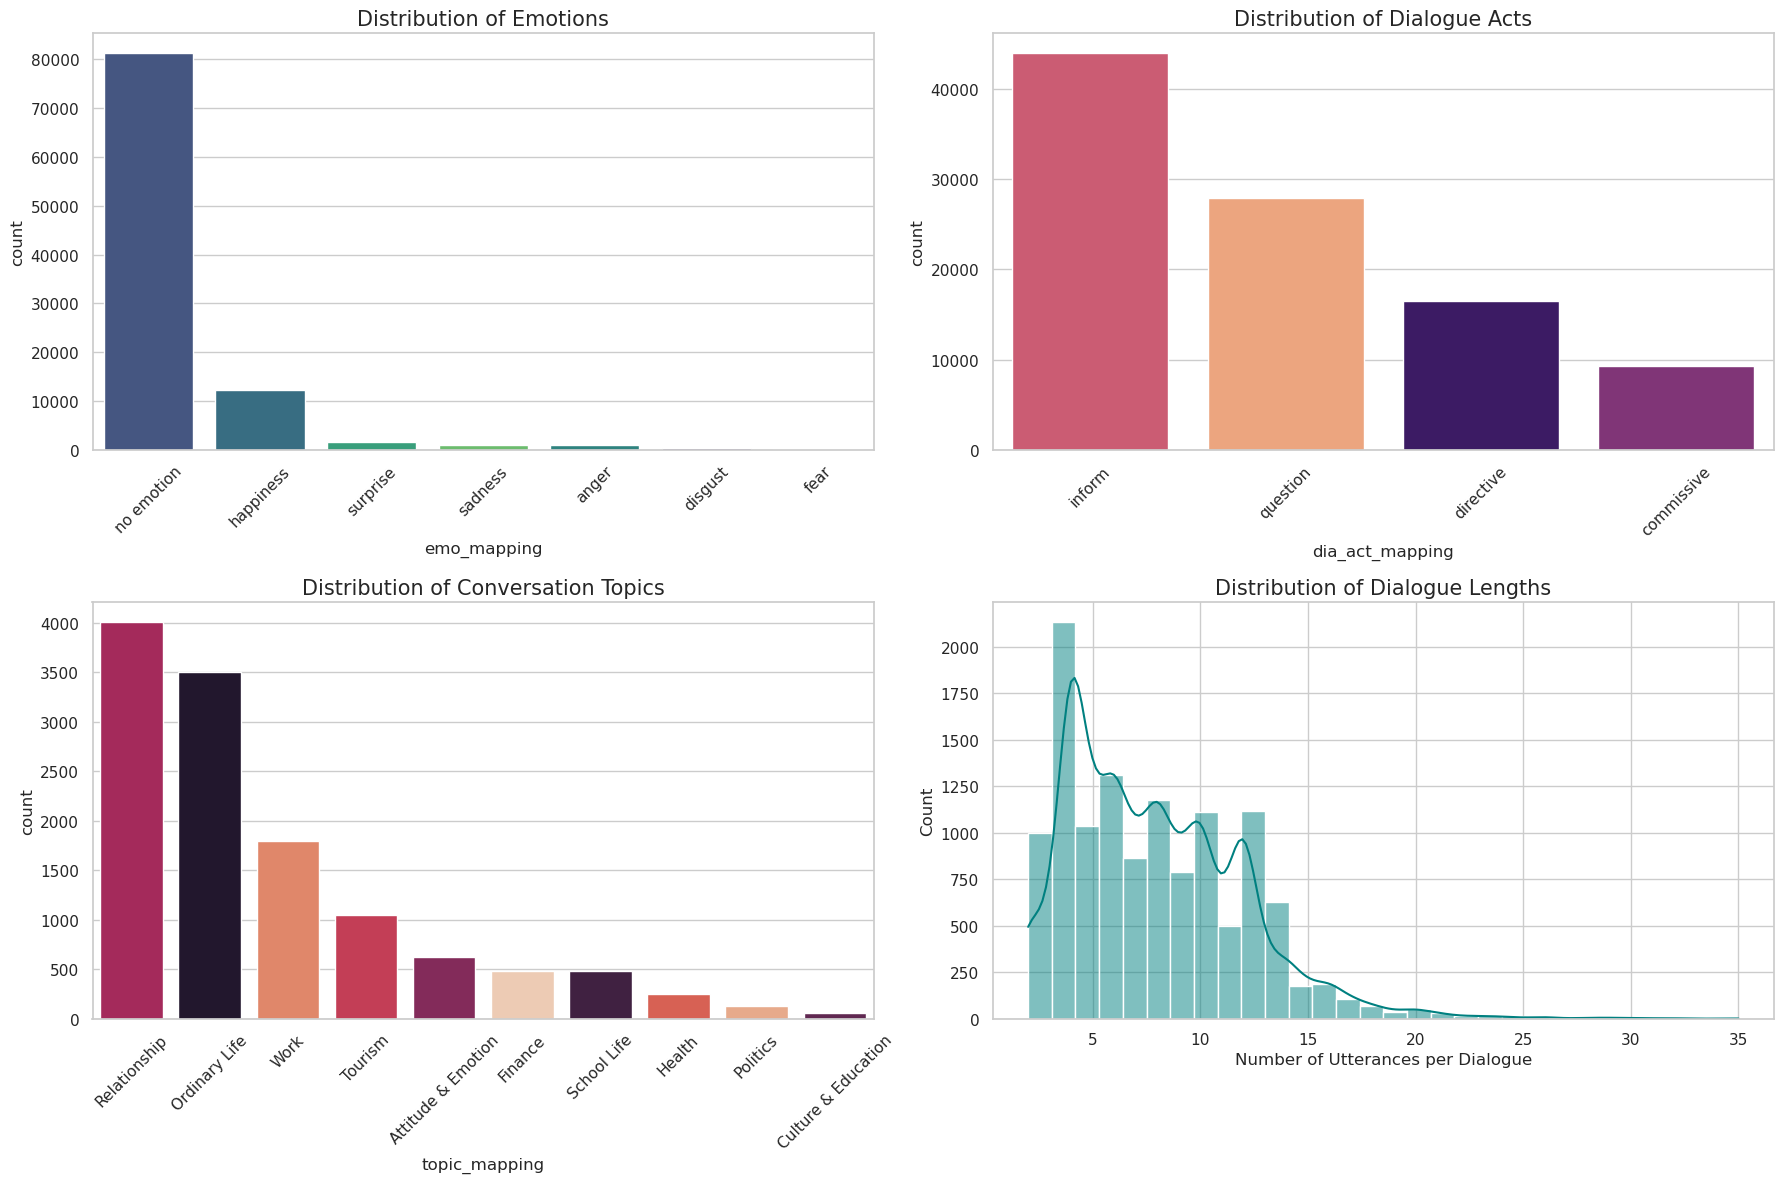

In [ ]:
df_counts = create_mapped_df(count_data, {'emotion_count': ('emo_mapping', emotion_mapping),
                                          'dia_act_count': ('dia_act_mapping', act_mapping)})

df_utt_top_counts = create_mapped_df(utt_topic_data, {'topic_counts': ('topic_mapping', topic_mapping)})

df = df.reset_index(drop=True)
df['topic_mapping'] = df_utt_top_counts['topic_mapping']
df['num_utterance'] = df_utt_top_counts['utt_counts']

plot_dialogue_distributions(df, counts_df=df_counts)

In [ ]:
df[['num_utterance','Dialogue_length']].describe()

,num_utterance,Dialogue_length
count,12376.000000,12376.000000
mean,7.890433,525.679379
std,4.023621,363.486790
min,2.000000,33.000000
25%,4.000000,256.000000
50%,7.000000,442.000000
75%,10.000000,693.000000
max,35.000000,4221.000000


In [ ]:
df[['num_utterance','Dialogue_length']].quantile(q=np.arange(0,1.01,0.25))

,num_utterance,Dialogue_length
0.00,2.0,33.0
0.25,4.0,256.0
0.50,7.0,442.0
0.75,10.0,693.0
1.00,35.0,4221.0


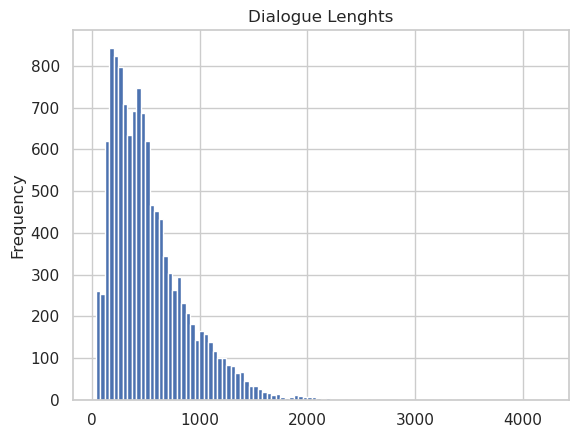

In [ ]:
df['Dialogue_length'].plot(kind='hist',bins=100, title="Dialogue Lenghts")
plt.show()

#### No Emotion

In [ ]:
#Identify dialogues where all utterances have an emotion label of 0 ('no emotion')
df_no_emotion = df[df['Emotion'].apply(lambda x: np.sum(x) == 0)].reset_index(drop=True)
print(df_no_emotion.info())
display(df_no_emotion[['num_utterance','Dialogue_length']].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5906 entries, 0 to 5905
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Dialogue         5906 non-null   object
 1   Emotion          5906 non-null   object
 2   Dialogue_Act     5906 non-null   object
 3   Topic            5906 non-null   int64 
 4   Dialogue_length  5906 non-null   int64 
 5   topic_mapping    5906 non-null   object
 6   num_utterance    5906 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 323.1+ KB
None


,num_utterance,Dialogue_length
count,5906.000000,5906.000000
mean,6.988317,476.975787
std,3.663588,349.183475
min,2.000000,33.000000
25%,4.000000,224.000000
50%,6.000000,387.000000
75%,10.000000,631.000000
max,32.000000,4221.000000


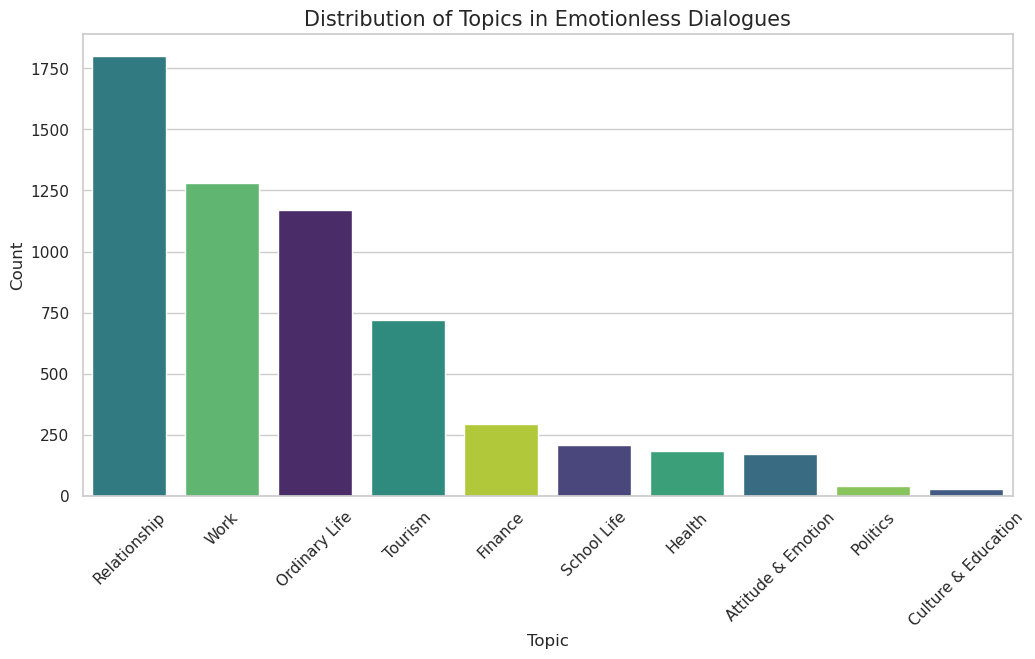

In [ ]:
#Calculate topic frequency and plot for the emotionless subset
plt.figure(figsize=(12, 6))
sns.countplot(data=df_no_emotion, x='topic_mapping', hue='topic_mapping',
              order=df_no_emotion['topic_mapping'].value_counts().index, palette='viridis', legend=False)
plt.title('Distribution of Topics in Emotionless Dialogues', fontsize=15)
plt.xticks(rotation=45)
plt.xlabel('Topic')
plt.ylabel('Count')
plt.show()

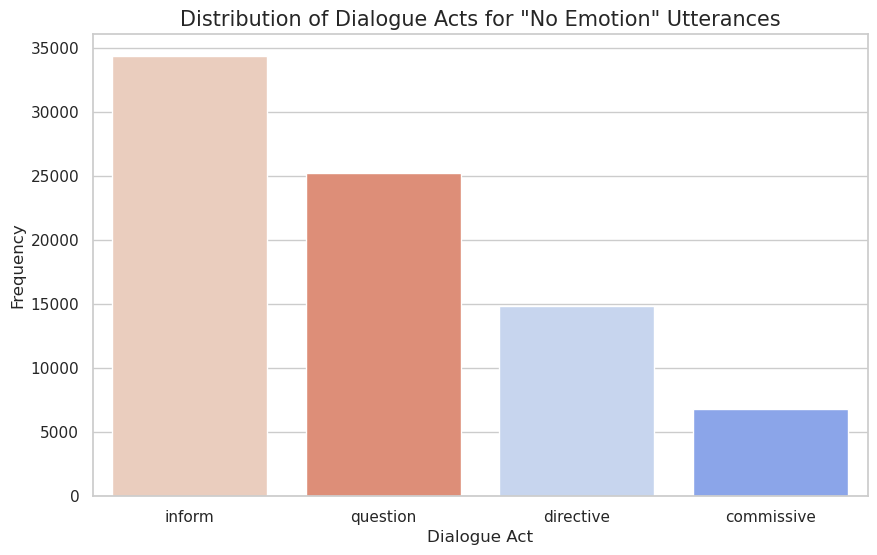

In [ ]:
#Create a subset of df_counts for utterances labeled as 'no emotion'
df_neutral_utterances = df_counts[df_counts['emo_mapping'] == 'no emotion']

#Generate a bar plot for dialogue acts in neutral utterances
plt.figure(figsize=(10, 6))
sns.countplot(data=df_neutral_utterances, x='dia_act_mapping', hue='dia_act_mapping',
              order=df_neutral_utterances['dia_act_mapping'].value_counts().index, palette='coolwarm', legend=False)
plt.title('Distribution of Dialogue Acts for "No Emotion" Utterances', fontsize=15)
plt.xlabel('Dialogue Act')
plt.ylabel('Frequency')
plt.show()

In [ ]:
print(f'Number of dialogues with no emotion: {len(df_no_emotion)}')
print(f'Number of neutral utterances analyzed: {len(df_neutral_utterances)}')

Number of dialogues with no emotion: 5906
Number of neutral utterances analyzed: 81256


### Dialogue Act Investigation

#### Bi-Turn Flow

In [ ]:
df_bi_flow = df[df['Dialogue_Act'].apply(len) == 2]

len(df_bi_flow)

563

In [ ]:
#checking for question --> commisive
for i, actions in enumerate(df.Dialogue_Act):
  if actions == [1,4]:
    print(df.Dialogue.iloc[i])

In [ ]:
bi_flow_counts, bi_flow_utt = collect_counts(df_bi_flow)
df_bi_flow_counts = create_mapped_df(bi_flow_counts, {'emotion_count': ('emo_mapping', emotion_mapping),
                                          'dia_act_count': ('dia_act_mapping', act_mapping)})
df_bi_flow_utt_top_counts = create_mapped_df(bi_flow_utt, {'utt_counts': ('topic_mapping', topic_mapping)})

In [ ]:
df_bi_flow_utt_top_counts.topic_mapping.value_counts()

topic_mapping
School Life    563
Name: count, dtype: int64

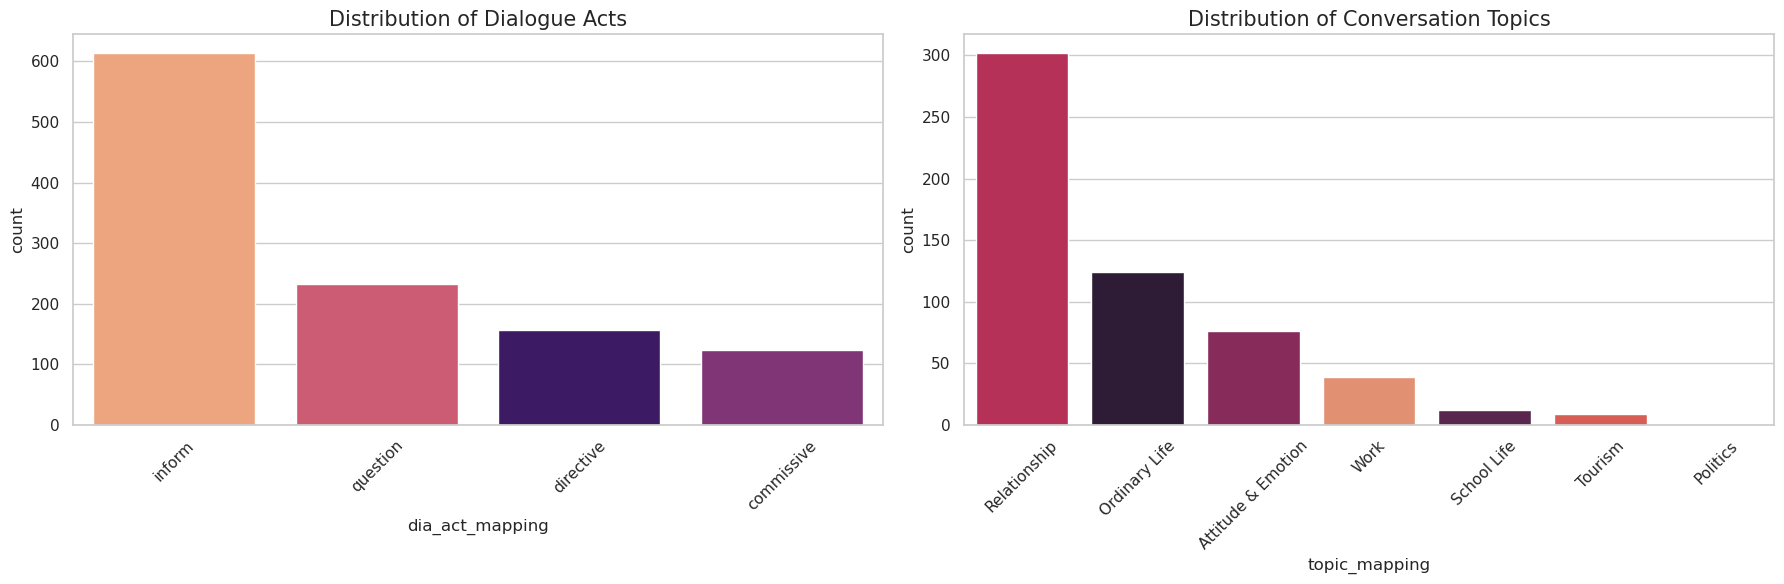

In [ ]:
plot_dialogue_distributions(df_bi_flow, counts_df=df_bi_flow_counts, length=False, emo=False)

### Truncated Data

In [ ]:
np.sum(df.Dialogue_length < MAX_CHAR_LENGTH)

df_shorter_length = df[df.Dialogue_length < MAX_CHAR_LENGTH]

df_shorter_length[['num_utterance','Dialogue_length']].describe()

,num_utterance,Dialogue_length
count,7149.000000,7149.000000
mean,5.701497,288.603161
std,2.576719,120.247511
min,2.000000,33.000000
25%,4.000000,191.000000
50%,5.000000,283.000000
75%,7.000000,394.000000
max,15.000000,499.000000


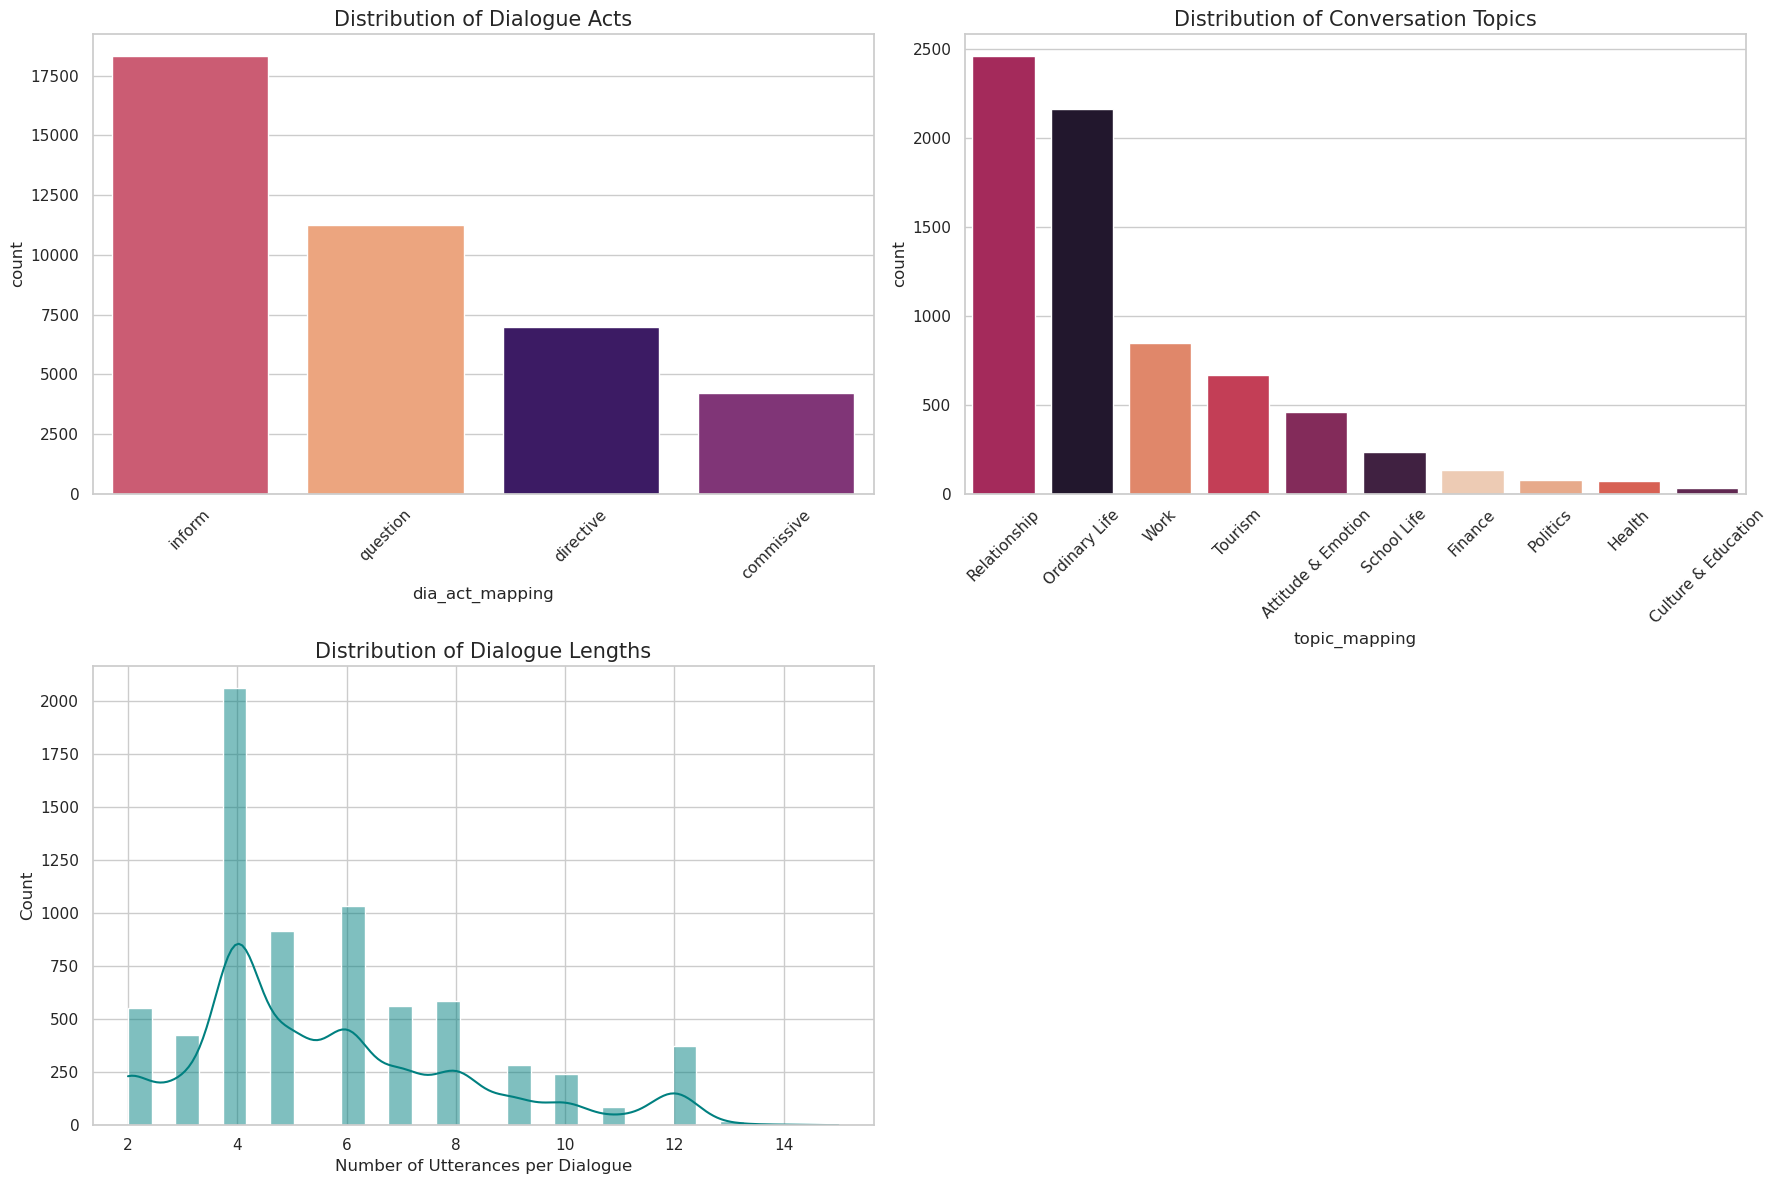

In [ ]:
shorter_counts, shorter_utt = collect_counts(df_shorter_length)
df_shorter_counts = create_mapped_df(shorter_counts, {'emotion_count': ('emo_mapping', emotion_mapping),
                                          'dia_act_count': ('dia_act_mapping', act_mapping)})
df_shorter_utt_top_counts = create_mapped_df(shorter_utt, {'utt_counts': ('topic_mapping', topic_mapping)})

plot_dialogue_distributions(df_shorter_length, counts_df=df_shorter_counts, length=True, emo=False)

### Further Pre-Processing

Train, validation, and test splits are made before separating utterances, to avoid cutting conversions. Checks are in place to remove mismatched rows (i.e. more labels than utterances).

Utterance lengths *after processing* show right-skewedness, mean of 43.6, and an IQR of 30\. The maximum length is 384, though 75% of utterances are below 55 characters long.

In [ ]:
df = df_shorter_length.copy()

df.drop(columns=['Emotion', 'topic_mapping' ], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7149 entries, 0 to 12371
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Dialogue         7149 non-null   object
 1   Dialogue_Act     7149 non-null   object
 2   Topic            7149 non-null   int64 
 3   Dialogue_length  7149 non-null   int64 
 4   num_utterance    7149 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 335.1+ KB


In [ ]:
def remove_mismatched_rows(df_to_check):#Re-written, partially by gemini intance
  """
  Checks for and removes rows where the number of dialogue acts does not match
  the pre-calculated number of utterances (__eou__ counts).
  This function is intended to be run on the dialogue-level DataFrame
  before utterances are extracted.
  """
  print(f'Initial number of dialogues: {len(df_to_check)}')
  print(f'Initial total number of utterances: {df_to_check.num_utterance.sum()}')

  # Create a mask for rows where the length of Dialogue_Act list doesn't match num_utterance
  mismatched_mask = df_to_check.apply(lambda row: len(row.Dialogue_Act) != row.num_utterance, axis=1)

  num_mismatched_rows = mismatched_mask.sum()

  if num_mismatched_rows > 0:
    print(f'Found {num_mismatched_rows} dialogues with mismatched Dialogue_Act labels and utterance counts.')
    print('Examples of mismatched rows (Dialogue_Act length vs num_utterance):')
    display(df_to_check[mismatched_mask][['Dialogue_Act', 'num_utterance']].head())
    df_to_check = df_to_check[~mismatched_mask].reset_index(drop=True)
    print(f'Removed {num_mismatched_rows} mismatched dialogue.')
    print(f'Remaining number of dialogues: {len(df_to_check)}')
    print(f'Remaining total number of utterances: {df_to_check.num_utterance.sum()}')
  else:
    print('No mismatched Dialogue_Act labels found. Data is consistent.')

  return df_to_check

In [ ]:
def utter_dict_build(df):
    '''Extracts utterances when context not used'''
    utter_dict = defaultdict(list)
    for dialogue in range(len(df)):
        for utt in range(df.num_utterance.iloc[dialogue]):
            utter_dict['utterance'].append(df.utterances.iloc[dialogue][utt])
            #utter_dict['emotion_label'].append(df.Emotion.iloc[dialogue][utt])
            utter_dict['dia_act_label'].append(df.Dialogue_Act.iloc[dialogue][utt])
            utter_dict['topic_label'].append(df.Topic.iloc[dialogue])
            utter_dict['utterance_length'].append(len(df.utterances.iloc[dialogue][utt]))

    return utter_dict

In [ ]:
def extract_utterances(df, context = False):
  '''LLM USAGE: Context section adapted from claude.ai chat --> https://claude.ai/share/873bf88b-95f6-42cc-a89d-f037e4840999
  Extracts utterances by splitting on __eou__
  If Context True, then contextual information is added to each utterance.

  Args:
    df: pd.DataFrame
    context: bool
  '''

  rows = defaultdict(list)
  for dialogue_id, dialogue in enumerate(df.Dialogue):#dialogue level
      utterances = dialogue.split('__eou__')[:-1]
      for turn_idx, utt in enumerate(utterances):#utterence level
        rows['dialogue_id'].append(dialogue_id)#_id
        rows['turn_idx'].append(turn_idx)#_id
        rows['utterances'].append(utt)
        rows['len_utterance'].append(len(utt))
        rows['num_utterance'].append(len(utterances))
        rows['topic_label'].append(df.Topic.iloc[dialogue_id])
        rows['dia_act_label'].append(df.Dialogue_Act.iloc[dialogue_id][turn_idx])
  df = pd.DataFrame(rows)
  # The remove_mismatched_rows function is now called externally before this function is invoked.
  # Therefore, no internal call is needed here.
  #Get prior context
  df['prior_utterance'] = df.groupby('dialogue_id')['utterances'].shift(1).fillna("")

  return df

#### Train/Test Split
- performed before utterance level to provide continuity
- dialydialog paper puts puts aside 1000/1000 for testing and validation

In [ ]:
split_point = int(len(df) * 0.16)#Based on ratio used in dailydialogue
print(split_point)

1143


In [ ]:
train_dial, temp_dial = train_test_split(df, test_size=split_point, random_state=42)
val_dial, test_dial = train_test_split(temp_dial, test_size=0.5, random_state=42)

print(train_dial.shape, val_dial.shape, test_dial.shape)

(6006, 5) (571, 5) (572, 5)


In [ ]:
#Call remove_mismatched_rows BEFORE extracting utterances
df = remove_mismatched_rows(df)

#Proceed with extracting utterances on the cleaned DataFrame
df = extract_utterances(df,context=True)
train_df = extract_utterances(train_dial, context=True)
val_df = extract_utterances(val_dial, context=True)
test_df = extract_utterances(test_dial, context=True)

Initial number of dialogues: 7149
Initial total number of utterances: 40760
No mismatched Dialogue_Act labels found. Data is consistent.


In [ ]:
'''FOR TESTING PURPOSES USE SMALLER PROPORTION OF DATA: 1 = Full, 4 = Quarter'''
MODIFYER = MODIFIYER_TEST
train_df = train_df[:int(len(train_df) / MODIFYER)]
val_df = val_df[:int(len(val_df) / MODIFYER)]
test_df = test_df[:int(len(test_df) / MODIFYER)]
print('Train: ',len(train_df))
print('Val: ',len(val_df))
print('Test: ',len(test_df))

Train:  34152
Val:  3276
Test:  3332


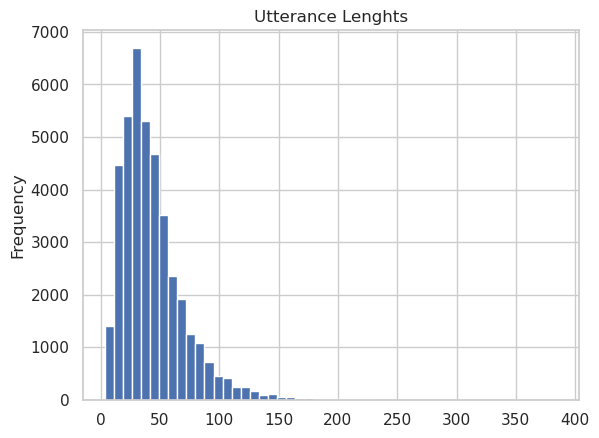

In [ ]:
df.len_utterance.plot(kind='hist',bins=50, title="Utterance Lenghts")
plt.show()

In [ ]:
df.len_utterance.describe()

count    40760.000000
mean        43.618842
std         27.068216
min          4.000000
25%         25.000000
50%         38.000000
75%         55.000000
max        384.000000
Name: len_utterance, dtype: float64

In [ ]:
#collect total number of label types
#num_emotions = int(training_dataset['emotion_label'].max() + 1)
num_acts = int(train_df['dia_act_label'].max() + 1)
num_topics = int(train_df['topic_label'].max() + 1)
num_all_topics = num_acts + num_topics # + num_emotions
num_all_topics

16

## Model Architecture and Selection of Hyperparameters
A RoBERTa base was chosen primarily for its performance in a similar task, outperforming other models on datasets containing fewer and greater utterances, although the dataset most comparable in size had more classes (Duran, Battle and Smith, 2021).

This implementation (`MultiHeadRoberta`) uses two classification heads (`da_head`, `topic_head`), using `current` and `prior` context during encoding (`DialogueDataset`) (Claude, 2026). Loss is evaluated using cross-entropy as they are multiclass (Pytorch, 2024). The sum of both heads is finally combined.

Dynamic padding (`DataCollatorWithPadding)`, pads to the longest sequence in each batch for further economy (huggingface, 2025).

#### Parameter-tuning

Smaller batch sizes are favoured \[8,16\], in contrast with the advice in the RoBERTa paper (Liu et al., 2019), and the fine tuning of the original BERT paper \[16, 32\]; this is an extension of a pre-existing model, so approximates fine-tuning. The original BERT paper offers three learning rate fine-tuning parameters (Devlin et al., 2019); this experiment uses similar, mirroring RoBERTa’s fine-tuning on the GLUE benchmark (Liu et al., 2019).

Layer freezing \[0,4,8\] is employed to avoid unnecessarily re-training, as is early stopping, (Nizam, 2020), (Claude, 2026).

CometML was used to optimize the model. 8 epochs were chosen for each sweep. (Duran, Battle and Smith, 2021\) use 10 per model, so early conservative experiments used 5, often failing to converge.

Parameters that reported the highest `f1_macro` score from the `da_head` (`da_macro_f1`) were selected for a final run of 12 epochs, as Comet visualisation suggested further possible improvements after 8\.

Finally, the model was uploaded to huggingface. The intention was to upload into the CSCT cloud, however environmental restraints prevented this. Final predictions from the Colab session were saved to CSV, and used here for display

COMET: [https://www.comet.com/isaac-fayle-waters/dailydialogue-mllv-full/](https://www.comet.com/isaac-fayle-waters/dailydialogue-mllv-full/)  
HF: [https://huggingface.co/Heterocliter/dailydialog\_roberta\_with\_context\_full](https://huggingface.co/Heterocliter/dailydialog_roberta_with_context_full)

#### Token Lengths for Analysis and Tokeniser Selection

In [ ]:
#Select tokenizer from pretrained
tokenizer = RobertaTokenizerFast.from_pretrained(MODEL_NAME)

In [ ]:
#Adjustments due to odd label mapping choice
for split in [train_df, val_df, test_df]:
    split['dia_act_label'] = split['dia_act_label'] - 1
    split['topic_label'] = split['topic_label'] - 1

In [ ]:
def combined_token_length(row):#From Claude
    '''Examines the token lengths of utterences, and compares them agains limits'''
    enc = tokenizer(
        str(row['prior_utterance']),
        str(row['utterances']),
        truncation=False
    )
    return len(enc['input_ids'])

df['combined_tokens'] = df.apply(combined_token_length, axis=1)

print(df['combined_tokens'].describe())
print(f"\nExceeds 128: {(df['combined_tokens'] > 128).sum()} ({100*(df['combined_tokens'] > 128).mean():.1f}%)")
print(f"Exceeds 256: {(df['combined_tokens'] > 256).sum()} ({100*(df['combined_tokens'] > 256).mean():.1f}%)")

count    40760.000000
mean        26.036187
std         10.406993
min          7.000000
25%         19.000000
50%         24.000000
75%         31.000000
max        114.000000
Name: combined_tokens, dtype: float64

Exceeds 128: 0 (0.0%)
Exceeds 256: 0 (0.0%)


### Model

#### Dataset Class for Context-Aware Encoding

In [ ]:
from torch.utils.data import Dataset as TorchDataset
class DialogueDataset(TorchDataset):
  '''Prepares data for encoding sentence pairs'''
  def __init__(self, df, tokenizer, max_length=MAX_LENGTH):
    self.df = df.reset_index(drop=True)
    self.tokenizer = tokenizer
    self.max_length = max_length

  def __len__(self):
    '''Compute steps per epoch'''
    return len(self.df)

  def __getitem__(self, idx):
    '''Get current and prior context and Tokenize'''
    row = self.df.iloc[idx]

    #utterence context
    current = str(row['utterances'])
    prior = str(row['prior_utterance'])

    #Tokenizing/encoding
    encoding = self.tokenizer(
        prior,
        current,
        truncation=True,
        max_length = self.max_length,
        padding = False
        )

    return {
        'input_ids': torch.tensor(encoding['input_ids']),
        'attention_mask': torch.tensor(encoding['attention_mask']),
        'da_labels' : torch.tensor(row['dia_act_label'],dtype=torch.long),
        'topic_labels': torch.tensor(row['topic_label'],dtype=torch.long)
    }

#### Model: Multi-Head RoBERTa

In [ ]:

class MultiHeadRoberta(nn.Module):
  '''RoBERTa encoder with two classification heads'''
  def __init__(self, model_name, num_da_labels, num_topic_labels):
    super().__init__()
    self.roberta = RobertaModel.from_pretrained(model_name)

    #Hidden layers size
    hidden_size = self.roberta.config.hidden_size

    #Seperation of linear layer for seperate heads
    self.da_head = nn.Linear(hidden_size, num_da_labels)
    self.topic_head = nn.Linear(hidden_size, num_topic_labels)

  def forward(self, input_ids, attention_mask,
              da_labels=None, topic_labels=None, **kwargs):

    #Extract classification token representation from final hidden layer
    outputs = self.roberta(input_ids, attention_mask=attention_mask)
    cls = outputs.last_hidden_state[:, 0, :]

    #Individual logits per head
    da_logits = self.da_head(cls)
    topic_logits = self.topic_head(cls)

    #Concatinate logits for compute_metrics
    combined_logits = torch.cat((da_logits, topic_logits), dim=1)

    loss = None
    if da_labels is not None and topic_labels is not None:
      loss_fn = nn.CrossEntropyLoss()
      #Sum of losses from both heads
      loss = loss_fn(da_logits, da_labels) + loss_fn(topic_logits, topic_labels)

    return {"loss":loss, "logits": combined_logits}

model = MultiHeadRoberta(MODEL_NAME, NUM_DA_LABELS, NUM_TOPIC_LABELS)

#### Tokenization

In [ ]:
def tokens_formated(dataset):#Adapted from claud.ai implementation
  prior = dataset['prior_utterance']
  current = dataset['utterances']
  tokenized = tokenizer(prior, current,padding="max_length", truncation=True, max_length=128)
  tokenized['labels'] = dataset["labels"]

In [ ]:
if not CSCT_CLOUD:
    training_dataset_ds = DialogueDataset(train_df, tokenizer)
    validation_dataset_ds = DialogueDataset(val_df, tokenizer)
    test_dataset_ds = DialogueDataset(test_df, tokenizer)

#### Function Definitions: Metrics and Training

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    da_labels = labels[0]
    topic_labels = labels[1]
    #split combined logits per head
    da_logits = logits[:, : NUM_DA_LABELS]
    topic_logits = logits[:, NUM_DA_LABELS:]

    #Get class index with Argmax
    da_preds = np.argmax(da_logits, axis=1)
    topic_preds = np.argmax(topic_logits, axis=1)

    #Get labels
    #da_labels = labels[:, 0]
    #topic_labels = labels[:, 1]

    #Get f1 scores
    da_f1 = f1_score(da_labels, da_preds, average='macro')
    topic_f1 = f1_score(topic_labels, topic_preds, average='macro')

    return {
        "da_macro_f1": da_f1,
        "topic_macro_f1": topic_f1
    }

In [ ]:
def apply_freezing(model, n_frozen):#From claude
    '''Freezing layers to lessen compute/time'''
    for param in model.roberta.embeddings.parameters():
        param.requires_grad = False
    for i, layer in enumerate(model.roberta.encoder.layer):
        if i < n_frozen:
            for param in layer.parameters():
                param.requires_grad = False
    return model

In [ ]:
#Data Collator: Pads each batch to the length of its longest sequence rather than max
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

### Experiment

#### Config for Comet Optimization

In [ ]:
config = {
    "algorithm": "bayes",
    "parameters": {
        "learning_rate": {
            "type": "discrete",
            "values": [1e-5, 2e-5, 3e-5]
        },
        "num_frozen_layers": {
            "type": "discrete",
            "values": [0, 4, 8]
        },
        "batch_size": {
            "type": "discrete",
            "values": [8, 16]
        }
    },
    "spec": {
        "metric": "da_macro_f1",
        "objective": "maximize"
    }
}
#Define comet optimisor using config
optimizer = Optimizer(config)

COMET INFO: 7391b804ea314923ae1f990c4c4bf77b
COMET INFO: Using optimizer config: {'algorithm': 'bayes', 'configSpaceSize': 18, 'endTime': None, 'id': '7391b804ea314923ae1f990c4c4bf77b', 'lastUpdateTime': None, 'maxCombo': 0, 'name': '7391b804ea314923ae1f990c4c4bf77b', 'parameters': {'batch_size': {'type': 'discrete', 'values': [8, 16]}, 'learning_rate': {'type': 'discrete', 'values': [1e-05, 2e-05, 3e-05]}, 'num_frozen_layers': {'type': 'discrete', 'values': [0, 4, 8]}}, 'predictor': None, 'spec': {'gridSize': 10, 'maxCombo': 0, 'metric': 'da_macro_f1', 'minSampleSize': 100, 'objective': 'maximize', 'retryAssignLimit': 0, 'retryLimit': 1000}, 'startTime': 3494175, 'state': {'mode': None, 'seed': None, 'sequence': [], 'sequence_i': 0, 'sequence_pid': None, 'sequence_retry': 0, 'sequence_retry_count': 0}, 'status': 'running', 'suggestion_count': 0, 'trials': 1, 'version': '2.1.10'}


#### Training Sweep

In [ ]:
OUT_DIR = "./content/drive/MyDrive/Uni-Masters/MLLV/dailydialogue/model/roberta_bi_head_full"

SWEEP = False
if SWEEP:
  #Configs
  METRIC_FOR_BEST = "da_macro_f1"
  GREATER = None
  for experiment in optimizer.get_experiments(project_name=PROJECT_NAME):
    lr = experiment.get_parameter("learning_rate")
    num_frozen = experiment.get_parameter("num_frozen_layers")
    bs = experiment.get_parameter("batch_size")

    #Rebuild model in loop
    model = MultiHeadRoberta(MODEL_NAME, NUM_DA_LABELS, NUM_TOPIC_LABELS)

    #Apply Freezing to layers to economise
    model = apply_freezing(model, num_frozen)

    #Rebuild trainer each loop with i parameters
    args = TrainingArguments(
        output_dir="./content/drive/MyDrive/Uni-Masters/MLLV/dailydialogue/model/roberta_sweep_full",
        report_to="comet_ml",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        learning_rate=lr,
        per_device_train_batch_size=bs,
        num_train_epochs=NUM_EPOCHS,
        load_best_model_at_end=True,
        metric_for_best_model=METRIC_FOR_BEST,
        greater_is_better=GREATER,
        remove_unused_columns=False,
        seed=42
    )

    trainer = Trainer(
      model=model,
      args=args,
      train_dataset= training_dataset_ds,
      eval_dataset= validation_dataset_ds,
      data_collator=data_collator,
      compute_metrics=compute_metrics,
      #Stop training if no improvement after 2 epochs
      callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
    )
    trainer.train()
    best_val_f1 = trainer.state.best_metric
    experiment.log_metric("da_macro_f1", best_val_f1)

    experiment.end()

#### Extended Final Training on Best Parameters: Save Weights and Upload to HF

In [ ]:
FINAL = False

if FINAL:
  # Best params from sweep
  best_params = {
    "learning_rate": 2e-05,
    "batch_size": 16,
    "num_frozen_layers": 0
  }

  lr = best_params["learning_rate"]
  num_frozen = best_params["num_frozen_layers"]
  bs = best_params["batch_size"]

  model = MultiHeadRoberta(MODEL_NAME, NUM_DA_LABELS, NUM_TOPIC_LABELS)
  model = apply_freezing(model, num_frozen)

  final_experiment = comet_ml.Experiment(project_name="dailydialogue-mllv-full")
  final_experiment.log_parameters({
    "run_type": "final",
    "learning_rate": best_params['learning_rate'],
    "num_frozen_layers": best_params['num_frozen_layers'],
    "batch_size": best_params['batch_size'],
  })

  args = TrainingArguments(
      output_dir=OUT_DIR,
      report_to="comet_ml",
      num_train_epochs = 12,
      eval_strategy="epoch",
      save_strategy="epoch",
      logging_steps=50,
      learning_rate=best_params['learning_rate'],
      per_device_train_batch_size=best_params['batch_size'],
      load_best_model_at_end=True,
      metric_for_best_model="da_macro_f1",
      remove_unused_columns=False,
      seed=42
  )

  trainer = Trainer(
      model=model,
      args=args,
      train_dataset= training_dataset_ds,
      eval_dataset= validation_dataset_ds,
      data_collator=data_collator,
      compute_metrics=compute_metrics,
      callbacks=[EarlyStoppingCallback(early_stopping_patience=5)]
  )
  trainer.train()

  #Save weights locally
  torch.save(model.state_dict(), './content/drive/MyDrive/Uni-Masters/MLLV/dailydialogue/model/da_model_weights_full.pth')
  #Save to hugging face
  model.roberta.push_to_hub("Heterocliter/dailydialog_roberta_with_context_full")
  tokenizer.push_to_hub("Heterocliter/dailydialog_roberta_with_context_full")

  #Upload full model weights as a separate file
  api = HfApi()
  api.upload_file(
      path_or_fileobj="./content/drive/MyDrive/Uni-Masters/MLLV/dailydialogue/model/da_model_weights_full.pth",
      path_in_repo="model_weights.pt",
      repo_id="Heterocliter/dailydialog_roberta_with_context_full"
  )

  final_experiment.end()

## Model Evaluation and Results

#### Overall

`Da_macro_f1` is the most important metric, as dialogue act classification is the main focus; Topic classification is secondary. This is perhaps reflected in the results: **Overall** **accuracy** is **83.5%** for DA classification, while Topic classification is **52.2%**. `da_macro_f1` is **78.1%**, while `topic_macro_f1` is **36.1%**.

However, class imbalance is likely a deciding factor, as shown below.

#### Topic

The classification report support shows that ‘Ordinary Life’ (F1: 60.4%) is over-represented in the test data; a trend not mirrored in earlier graphs showing ‘Relationship’ as highest. Correspondingly recall is moderate for both (63.6%, 63.1%), though the confusion matrix for Topic shows cross-misclassification between the two was common.

#### Dialogue Act

The distribution of Inform and Question classes evident in graphing above is reflected in the classification report support column. Glancing at the confusion matrix might suggest higher F1 for Inform, however this is due to higher support: **Question** actually receives **92.5% F1**; Inform 87.2%.

Sample frequency is still evidently important.

#### Limitations

Focusing solely on Dialogue Act classification may improve the overall outcome, as inclusion of Topic possibly skews the loss function.

Greater efforts should have been made to ensure that the correct libraries were used before migrating the system into the CSCT cloud. Though it is unlikely to have altered the results significantly, the results are not reflective of the environment they are displayed within (un-true if now viewing on github).

Further comparisons may have been useful: comparing the model with a non-contextual model, heavier pre-processing, layer variance.

Predictions are from a single run: std and mean could have been compared if further predictive runs had been made, and a clearer representation of the model presented.   

The contextual element makes the model less useful outside of this experiment.

#### Carbon Emissions

A conservative estimate of 1.86 kg eq.CO2  was emitted during the training of this model (Lacoste et al., 2019). Further details and partial system information available from HF link.

In [ ]:
pred_path = '../data/roberta_multi_test/predictions.csv'
results_df = pd.read_csv(pred_path)


In [ ]:
da_preds = results_df['da_preds'].values
da_labels = results_df['da_labels'].values
topic_preds = results_df['topic_preds'].values
topic_labels = results_df['topic_labels'].values

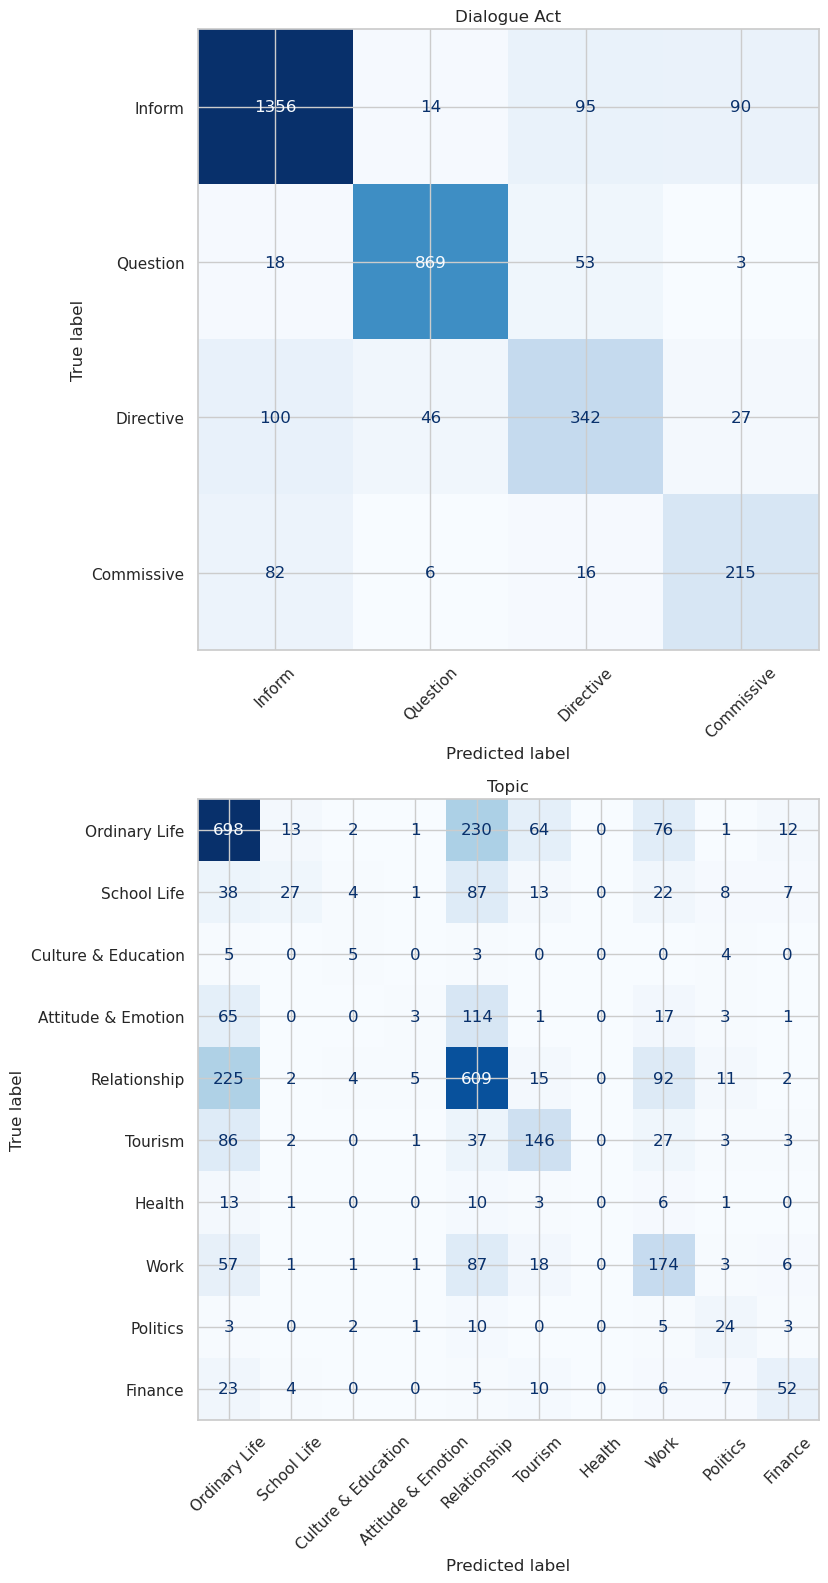

In [ ]:
#Confusion matrices
da_names = ['Inform', 'Question', 'Directive', 'Commissive']
topic_names = [topic_mapping[i+1] for i in range(NUM_TOPIC_LABELS)]

fig, axes = plt.subplots(2, 1, figsize=(16, 16))

ConfusionMatrixDisplay(
    confusion_matrix(da_labels, da_preds),
    display_labels=da_names
).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Dialogue Act')
axes[0].tick_params(axis='x', rotation=45)

ConfusionMatrixDisplay(
    confusion_matrix(topic_labels, topic_preds),
    display_labels=topic_names
).plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Topic')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
#F1 scores
da_f1 = f1_score(da_labels, da_preds, average='macro')
topic_f1 = f1_score(topic_labels, topic_preds, average='macro')
print('_'*70)
print(f"DA Macro F1:    {da_f1:.4f}")
print('--'*35)
print(f"Topic Macro F1: {topic_f1:.4f}")
print('_'*70)

______________________________________________________________________
DA Macro F1:    0.7812
----------------------------------------------------------------------
Topic Macro F1: 0.3614
______________________________________________________________________


In [ ]:
#Accuracy per task
da_acc = accuracy_score(da_labels, da_preds)
topic_acc = accuracy_score(topic_labels, topic_preds)
print('_'*70)
print(f"DA Accuracy:    {da_acc:.4f}")
print('--'*35)
print(f"Topic Accuracy: {topic_acc:.4f}")
print('_'*70)

#Per-class breakdown
print("\n--- Dialogue Act ---")
print(classification_report(
    da_labels, da_preds,
    target_names=da_names,
    digits=3
))

print("\n--- Topic ---")
print(classification_report(
    topic_labels, topic_preds,
    target_names=topic_names,
    digits=3
))

______________________________________________________________________
DA Accuracy:    0.8349
----------------------------------------------------------------------
Topic Accuracy: 0.5216
______________________________________________________________________

--- Dialogue Act ---
              precision    recall  f1-score   support

      Inform      0.871     0.872     0.872      1555
    Question      0.929     0.922     0.925       943
   Directive      0.676     0.664     0.670       515
  Commissive      0.642     0.674     0.657       319

    accuracy                          0.835      3332
   macro avg      0.780     0.783     0.781      3332
weighted avg      0.836     0.835     0.835      3332


--- Topic ---
                     precision    recall  f1-score   support

      Ordinary Life      0.575     0.636     0.604      1097
        School Life      0.540     0.130     0.210       207
Culture & Education      0.278     0.294     0.286        17
 Attitude & Emotion     

/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/conda/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# **References**

Claude (2026) *Multi-turn patterns in dialogue act classification* *Claude Sonnet 4.6. INITIAL PROMPT: ‘Can information about multi-turn patterns or bi-turn flows improve dialogue act classification I some way?’* 2026 \[online\]. Available from: https://claude.ai/share/3beb1d4b-bd78-4749-9924-6a495cd8e621 \[Accessed 12 April 2026\].

Devlin, J., Chang, M.-W., Lee, K. and Toutanova, K. (2019) *Bert: Pre-training of deep bidirectional transformers for language understanding understanding*. In: *Proceedings of the 2019 conference of the North American chapter of the association for computational linguistics: human language technologies*. 1, pp. 4171–4186.

Duran, N., Battle, S. and Smith, J. (2021) Sentence Encoding for Dialogue Act Classification. *Natural Language Engineering* \[online\]. 29 (3), pp. 794–823. \[Accessed 18 March 2026\].

FacebookAI (2024) *FacebookAI/roberta-base · Hugging Face* *huggingface.co*. 18 January 2024 \[online\]. Available from: https://huggingface.co/FacebookAI/roberta-base \[Accessed 10 April 2026\].

huggingface (2025) *transformers/src/transformers/data/data\_collator.py at v5.6.2 · huggingface/transformers* *GitHub*. 2025 \[online\]. Available from: https://github.com/huggingface/transformers/blob/v5.6.2/src/transformers/data/data\_collator.py\#L191 \[Accessed 15 April 2026\].

Lacoste, A., Luccioni, A., Schmidt, V. and Dandres, T. (2019) *Quantifying the Carbon Emissions of Machine Learning* *https://arxiv.org/abs/1910.09700*. \[Accessed 25 April 2026\].

Li, Y., Su, H., Shen, X., Li, W., Cao, Z. and Niu, S. (2017) Dailydialog: a Manually Labelled multi-turn Dialogue dataset. *Proceedings of the Eighth International Joint Conference on Natural Language Processing*. 1, pp. 986–995.

Liu, Y. *et al.* (2019) *Roberta: a Robustly Optimized BERT Pretraining Approach* *arXiv:1907.11692* \[online\]. Available from: https://arxiv.org/pdf/1907.11692 \[Accessed 8 April 2026\].

Nizam (2020) *What is freezing/unfreezing a layer in neural networks?* *Stack Overflow*. 6 June 2020 \[online\]. Available from: https://stackoverflow.com/a/62229277 \[Accessed 25 April 2026\].

OpenAI (no date) *OpenAI API* *platform.openai.com* \[online\]. Available from: https://platform.openai.com/tokenizer \[Accessed 10 April 2026\].

Pytorch (2024) *CrossEntropyLoss — PyTorch 2.7 Documentation* *Pytorch.org*. 2024 \[online\]. Available from: https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html \[Accessed 11 April 2026\].

Radford, A., Wu, J., Child, R., Luan, D., Amodei, D. and Sutskever, I. (2019) Language Models Are Unsupervised Multitask Learners. *OpenAI blog*. 1 (8), p. 9\.


## Appendix

#### LLM USAGE:

An interest in using dialogue flow patterns led to a ‘dialogue flow’ with [Claude.ai](http://Claude.ai) (Sonnet 4.6) in which the multitask classification and context-aware customisations were introduced, partially through de-bugging and trial and error. Solutions that reduced overall compute were requested and prioritised.

Many of the graphing functions were generated on request (Claude, Gemini, ChatGPT), though a piece by piece approach is always followed, and the direction of the project is governed by its author.  

## Relevant Prompts From Model Creation Dialogue

1\. Can information about multi-turn patterns or bi-turn flows improve dialogue act classification in some way?

6\. Is this sort of process quite common? If so, is it mentioned in relevant influential papers? I remember something to do with tags in Attention is All You Need, for example.

8\. So what other approaches have been tried with the DailyDialog dataset, within the last few years?

23\. Well, I'm limiting the length for the moment, mostly as a means to preserve compute. I might do a full run with credits at the end, but being economical is sort of encouraged.

25\. OK, can you put it all together please? Add comments so I can see what I'm implementing, although I get what's going on.

39\. How much freedom do you get with CometML? Also, how many words roughly is the max of 128 tokens?

45\. What does batch size mean in this context?

46\. Yes. Is there such a thing as adaptable batch sizing?

47\. No, what is a data collator?

49\. Shouldn't I be splitting the data before I extract utterances?

79\. I see, I'm just trying to make sure I'm working from recognised patterns rather than ripping someone's work without realising it.

83\. Ah, I can't use torch.  

92\. One final task: please collect all of my prompts from this conversation. Where I've included code or debugging, or anything else quite long, please replace with an appropriate placeholder.

<div class="alert alert-success" style="color:black"><h3>Before you submit this notebook to NBGrader for marking:</h3>

1. Make sure have completed all exercises marked by <span style="color:blue">**blue cells**</span>.
2. For automatically marked exercises ensure you have completed any cells with `# YOUR CODE HERE`. Then click 'Validate' button above, or ensure all cells run without producing an error.
3. For manually marked exercises ensure you have completed any cells with `"YOUR ANSWER HERE"`.
4. Ensure all cells are run with their output visible.
5. Fill in your student ID (**only**) below.
6. You should now **save and download** your work.

</div>

**Student ID:** 16020297